Loaded snapshots: 19


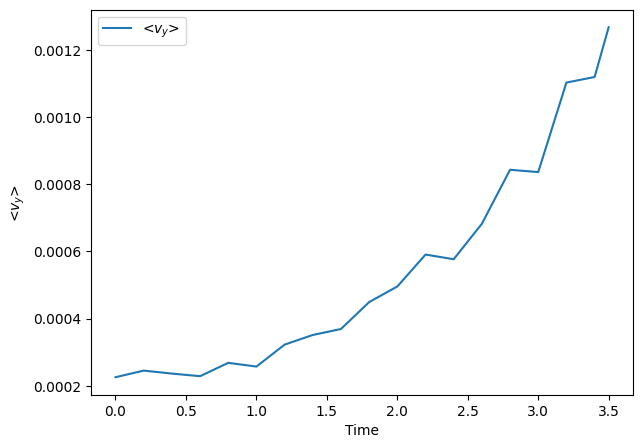

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import glob
from matplotlib.animation import FFMpegWriter




# =========================================================
# Read one snapshot file
# =========================================================
def read_snapshot(filename):

    with open(filename, 'rb') as f:

        # -------------------------------------------------
        # Header
        # -------------------------------------------------
        time = np.fromfile(f, dtype=np.float64, count=1)[0]

        nx = np.fromfile(f, dtype=np.int32, count=1)[0]
        ny = np.fromfile(f, dtype=np.int32, count=1)[0]

        nhydro = np.fromfile(f, dtype=np.int32, count=1)[0]
        nmhd   = np.fromfile(f, dtype=np.int32, count=1)[0]

        # -------------------------------------------------
        # Grid
        # -------------------------------------------------
        xv = np.fromfile(f, dtype=np.float64, count=nx)
        yv = np.fromfile(f, dtype=np.float64, count=ny)

        # -------------------------------------------------
        # Hydro variables
        # shape = (6,nx,ny)
        # -------------------------------------------------
        hydro = np.fromfile(
            f,
            dtype=np.float32,
            count=nhydro * nx * ny
        )

        hydro = hydro.reshape((nhydro, nx, ny), order='F')

        # -------------------------------------------------
        # MHD variables
        # shape = (4,nx,ny)
        # -------------------------------------------------
        mhd = np.fromfile(
            f,
            dtype=np.float32,
            count=nmhd * nx * ny
        )

        mhd = mhd.reshape((nmhd, nx, ny), order='F')

    # -------------------------------------------------
    # Extract variables
    # -------------------------------------------------
    rho = hydro[0]
    vx  = hydro[1]
    vy  = hydro[2]
    vz  = hydro[3]
    prs = hydro[4]
    scl = hydro[5]

    bx  = mhd[0]
    by  = mhd[1]
    bz  = mhd[2]
    psi = mhd[3]

    return {
        'time': time,
        'nx': nx,
        'ny': ny,
        'xv': xv,
        'yv': yv,
        'rho': rho,
        'vx': vx,
        'vy': vy,
        'vz': vz,
        'prs': prs,
        'scl': scl,
        'bx': bx,
        'by': by,
        'bz': bz,
        'psi': psi,
    }


# =========================================================
# PATH TO SNAPSHOT FILES
# =========================================================
# Example:
# files = sorted(glob.glob('data/snap*.bin'))

files = sorted(glob.glob('/Users/kathan/Desktop/PhD Research/Code/2D/hdc/snap*.bin'))

print("Loaded snapshots:", len(files))


# =========================================================
# Read all snapshots
# =========================================================
snapshots = [read_snapshot(f) for f in files]


# =========================================================
# Initial snapshot
# =========================================================
snap0 = snapshots[0]

fig, ax = plt.subplots(figsize=(8,6))

im = ax.imshow(
    snap0['vy'].T,
    origin='lower',
    extent=[
        snap0['xv'][0],
        snap0['xv'][-1],
        snap0['yv'][0],
        snap0['yv'][-1]
    ],
    aspect='auto',
    animated=True
)

# ---------------------------------------------------------
# VERY IMPORTANT
# Fix color scale so animation becomes visible
# ---------------------------------------------------------
#im.set_clim(0.0, 1.1)

vmin = min(s['vy'].min() for s in snapshots)
vmax = max(s['vy'].max() for s in snapshots)

im.set_clim(vmin, vmax)

cbar = plt.colorbar(im)
cbar.set_label('Velocity in Y direction')

title = ax.set_title(f"Velocity in Y direction   t = {snap0['time']:.4f}")

ax.set_xlabel('x')
ax.set_ylabel('y')


# =========================================================
# Animation update
# =========================================================
def update(frame):

    snap = snapshots[frame]

    im.set_data(snap['vy'].T)

    title.set_text(f"Velocity in Y direction   t = {snap['time']:.4f}")

    return [im]


# =========================================================
# Create animation
# =========================================================
anim = FuncAnimation(
    fig,
    update,
    frames=len(snapshots),
    interval=300,
    blit=False
)

"""
for i, snap in enumerate(snapshots):
    print(
        i,
        snap['time'],
        snap['prs'].min(),
        snap['prs'].max()
        }
"""


plt.close(fig)

snapshots = [read_snapshot(f) for f in files]
times = []
gwr = []
vy_mean = []

for snap in snapshots:
    times.append(snap['time'])
    gwr.append(1.2e-3 * np.exp(1.49*snap['time']))
    vy_mean.append((np.mean(np.abs(snap['vy']))))

#print(snap['vy'])

plt.figure(figsize=(7,5))
#plt.plot(times, gwr, label='Aexp($\Gamma$ t)')
plt.plot(times, vy_mean, label='<$v_y$>')

plt.xlabel('Time')
plt.ylabel(f'<$v_y$>')
#plt.ylabel(f'Aexp($\Gamma$t)')
plt.legend()
plt.show()


writer = FFMpegWriter(fps=10, bitrate=1800)
#anim.save('HLL 2D MHD.mp4', writer=writer)
HTML(anim.to_jshtml())
